# Evaluation of the automatic linguistic annotation - Linguistic Annotation Using Language Models: Introduction

This notebook is published together with the lecture ***Linguistic Annotation Using Language Models: Introduction***, presented during the MECANO workshop "Workflows for Natural Language Processing" (Leuven, 17-19 November 2025).

The aim of this notebook is to perform the **evaluation of automatic linguistic annotation** performed on any language.
We recommend to use Google Colab to run the code.

Start by running the first cells to install the necessary packages and import them.

In [ ]:
!pip install pandas scikit-learn matplotlib seaborn

In [ ]:
from google.colab import files
import pandas as pd
import io
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

Run the cell to upload your file. The file must be in **.tsv** format.

The file must contain a column called `UPOS` containing the automatic linguistic tags and one called `Gold_UPOS` containing the corrected tag.

In [ ]:
#by running this cell you can select the tsv file you used for the manual evaluation from a local folder
uploaded = files.upload()

Saving syntactic_analysis_new.csv to syntactic_analysis_new.csv


In [ ]:
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]), sep="\t", comment="#")  # assuming TSV format
df = df[df["Gold_UPOS"].notna() & (df["Gold_UPOS"] != "") & (df["UPOS"].notna()) & (df["Gold_UPOS"] != "")] #only keeps rows for which Gold_UPOS and UPOS are filled

In [ ]:
#makes sure you have the Gold_UPOS and UPOS columns correctly named  (if error in the previous cell, this could be the problem)
print("Columns:", df.columns.tolist())
assert "UPOS" in df.columns and "Gold_UPOS" in df.columns, "File must have UPOS and Gold_UPOS columns"


Columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'UPOS', 'Gold_UPOS', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10']


Store the relevant columns in a variable.

In [ ]:
#this cell identifies the manually annotated data (y_true) and the automatically annotated ones (y_pred)
y_true = df["Gold_UPOS"]
y_pred = df["UPOS"]

Calculate the **POS tagging accuracy**. The explanation of the terminology can be found in the slides published with the code.

In [ ]:
#here you calculate the accuracy, i.e. the proportion of correctly annotated data
accuracy = accuracy_score(y_true, y_pred)
print(f"POS Tagging Accuracy: {accuracy:.4f}")

POS Tagging Accuracy: 0.0441


Create the **confusion matrix**

In [ ]:
#here we create the confusion matrix, showing how the different categories were labelled by the program
labels = sorted(set(y_true) | set(y_pred))
cm = confusion_matrix(y_true, y_pred, labels=labels)


In [1]:
#this is just to list all the labels you find in you manually annotated and automatically annotated data,
#to see if there aren't "strange" things
labels

NameError: name 'labels' is not defined

Display your confusion matrix.

In [ ]:
#display the confusion matrix as a pure matrix
cm

array([[ 6, 13,  6,  8,  2, 14, 23,  3,  1, 10,  7, 25,  3, 12,  3],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0

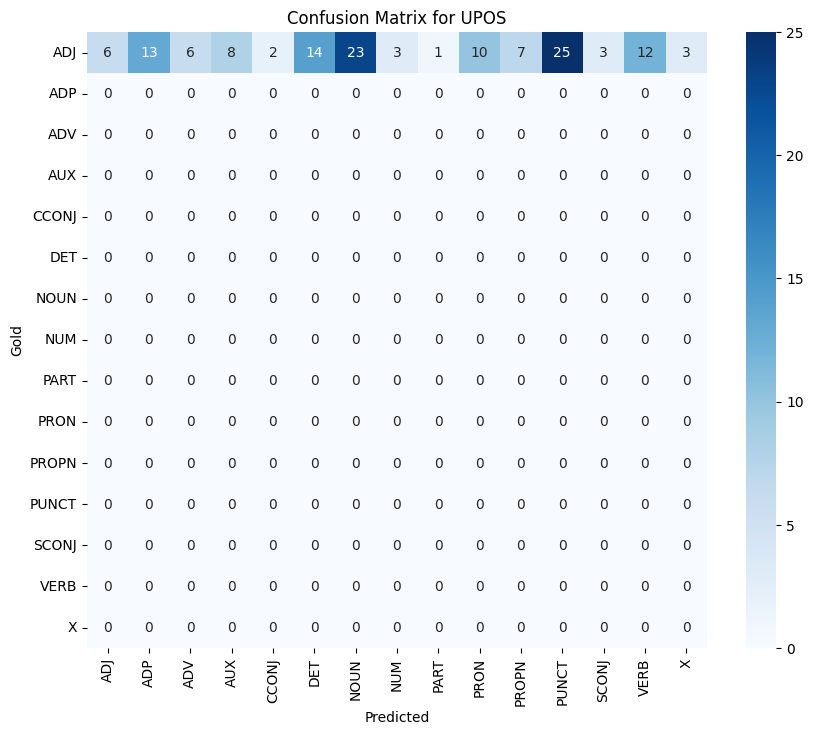

In [ ]:
#display the confusion matrix with nice colors

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Gold")
plt.title("Confusion Matrix for UPOS")
plt.show()


In [ ]:
#the classification report gives precision, recall, f1-score for every category (here, every POS). The support column indicates how many tokens were labeled with each of the POS in the gold data
print("\nClassification Report:")
print(classification_report(y_true, y_pred, labels=labels))



Classification Report:
              precision    recall  f1-score   support

         ADJ       1.00      0.04      0.08       136
         ADP       0.00      0.00      0.00         0
         ADV       0.00      0.00      0.00         0
         AUX       0.00      0.00      0.00         0
       CCONJ       0.00      0.00      0.00         0
         DET       0.00      0.00      0.00         0
        NOUN       0.00      0.00      0.00         0
         NUM       0.00      0.00      0.00         0
        PART       0.00      0.00      0.00         0
        PRON       0.00      0.00      0.00         0
       PROPN       0.00      0.00      0.00         0
       PUNCT       0.00      0.00      0.00         0
       SCONJ       0.00      0.00      0.00         0
        VERB       0.00      0.00      0.00         0
           X       0.00      0.00      0.00         0

    accuracy                           0.04       136
   macro avg       0.07      0.00      0.01       136
we

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
